# The Path Less Travelled

This notebook will contain all the driving code for my honours project including synthetic data generation, real data preprocessing, model training, and evaluation. 

In [1]:
#Imports
from wanderer import *
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf


Text(0.5, 1.0, 'Ornstein-Uhlenbeck Process Paths')

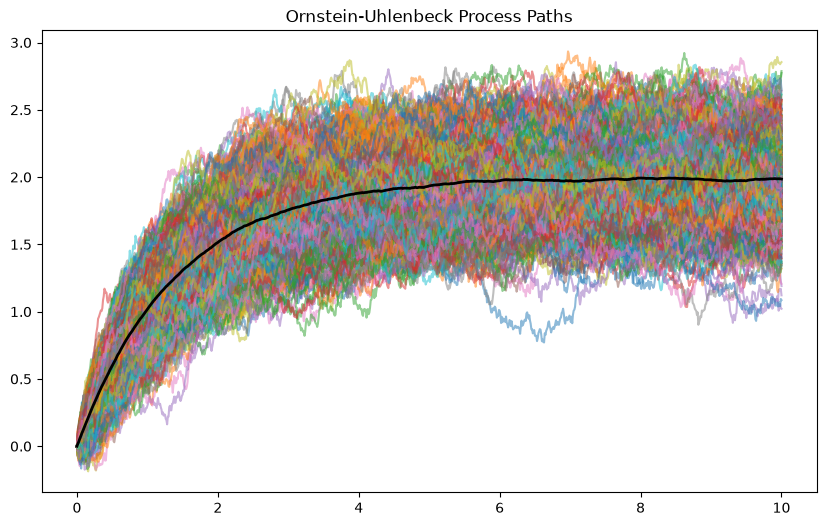

In [2]:
#Ornstein-Uhlenbeck Process simulation by Euler Marayuma method

#Define the drift and diffusion functions for the Ornstein-Uhlenbeck process
theta = 0.7
mu = 2
sigma = 0.3

def OUP_drift(X, t=None):
    return theta * (mu - X)

def OUP_diffusion(X, t=None):
    return sigma * np.ones_like(X)



OUP_generator = EulerMarayumaGenerator(drift_function=OUP_drift, diffusion_function=OUP_diffusion, initial_value=0, time_step=0.01, time_horizon=10, num_paths=1000, seed=126)

OUP_process = OUP_generator.generate_EulerMarayuma()

#Save to json
StochasticProcess.to_json( OUP_process, "OUP_process_EM.json")

#plot the Ornstein-Uhlenbeck process


#plot all paths and overlay the mean path
plt.figure(figsize=(10, 6))
for i in range(OUP_process.num_paths):
    plt.plot(OUP_process.timeGrid, OUP_process.paths[i], alpha=0.5)
plt.plot(OUP_process.timeGrid, OUP_process.timeMean, color='black', linewidth=2, label='Mean Path')
plt.title('Ornstein-Uhlenbeck Process Paths')

In [3]:
#Ornstein-Uhlenbeck Process simulation by Analytical method

#Define the parameters for the Ornstein-Uhlenbeck process
theta = 0.7
mu = 2
sigma = 0.3
initial_value = 0

#Define the time grid for the simulation
time_step = 0.01
time_horizon = 10
time_grid = np.arange(0, time_horizon + time_step, time_step)

#Define the number of paths to simulate
num_paths = 1000
seed = 126

#Simulate the Ornstein-Uhlenbeck process using the analytical solution and  the stochastic integral
OUP_analytical_paths = np.zeros((num_paths, len(time_grid)))
for i in range(num_paths):
    for t in range(1, len(time_grid)):
        def OUP_integrand(s):
            return np.exp(-theta * (time_grid[t] - s)) 

        OUP_analytical_paths[i, t] = initial_value * np.exp(-theta * time_grid[t]) + mu * (1 - np.exp(-theta * time_grid[t])) + sigma * stochastic_integral(OUP_integrand, 0, time_grid[t], time_step, seed = seed + i)


#Create stochastic process object for the analytical solution
OUP_analytical_process = StochasticProcess(paths=OUP_analytical_paths, timeHorizon=time_horizon, timeStep=time_step, num_paths=num_paths, method='Analytical')

#save to json
StochasticProcess.to_json(OUP_analytical_process, 'OUP_analytical_process.json')

#plot the Ornstein-Uhlenbeck process using the analytical solution and overlay the mean path
plt.figure(figsize=(10, 6))
for i in range(OUP_analytical_process.num_paths):
    plt.plot(OUP_analytical_process.timeGrid, OUP_analytical_process.paths[i], alpha=0.5)
plt.plot(OUP_analytical_process.timeGrid, OUP_analytical_process.timeMean, color='black', linewidth=2, label='Mean Path')
plt.title('Ornstein-Uhlenbeck Process Paths (Analytical Solution)')


KeyboardInterrupt: 

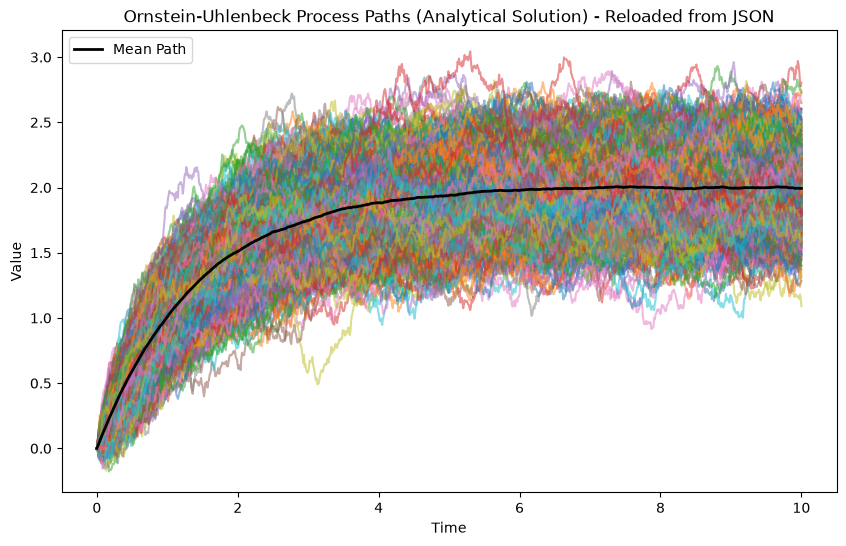

In [ ]:
# reload the json file and create a new StochasticProcess object
OUP_analytical_process_reloaded = StochasticProcess.from_json('OUP_analytical_process.json')

#plot the Ornstein-Uhlenbeck process using the analytical solution and overlay the mean path
plt.figure(figsize=(10, 6))
for i in range(OUP_analytical_process_reloaded.num_paths):
    plt.plot(OUP_analytical_process_reloaded.timeGrid, OUP_analytical_process_reloaded.paths[i], alpha=0.5)
plt.plot(OUP_analytical_process_reloaded.timeGrid, OUP_analytical_process_reloaded.timeMean, color='black', linewidth=2, label='Mean Path')
plt.title('Ornstein-Uhlenbeck Process Paths (Analytical Solution) - Reloaded from JSON')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

Text(0.5, 0, 'Time (Years)')

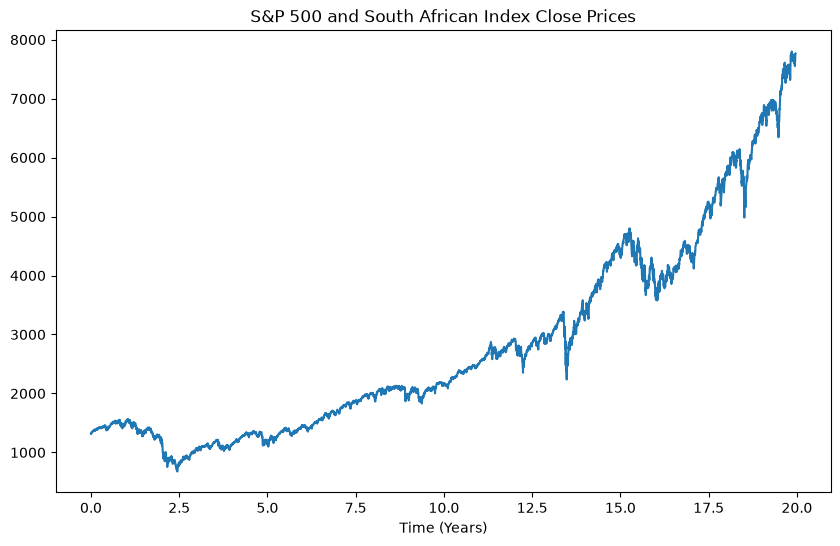

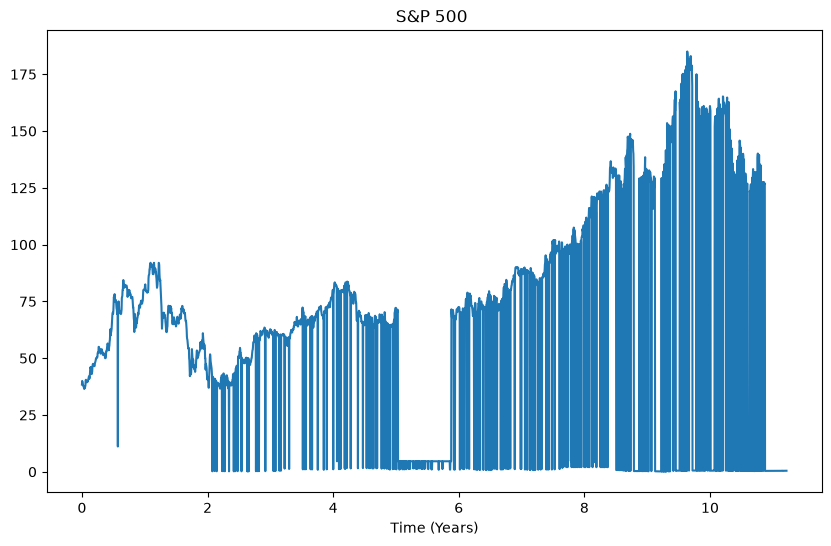

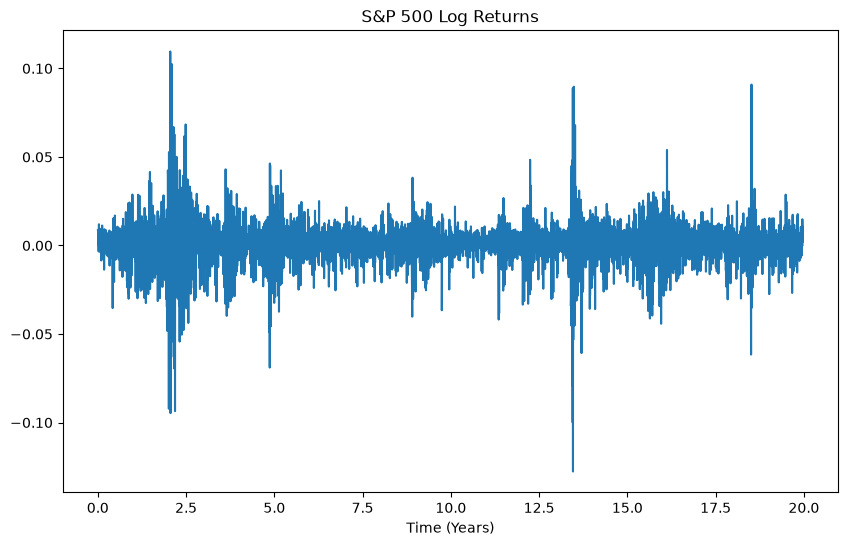

In [5]:


#pull daily sp&p 500 data for the last 20 years
sp500 = yf.Ticker("^GSPC")

#select only close prices 
sp500_close = sp500.history(period="20y")["Close"]
#create stochastic process object for the sp500 close prices
sp500_process = StochasticProcess(paths=sp500_close.values.reshape(1, -1), timeHorizon=len(sp500_close)/252, timeStep=1/252, num_paths=1, method='S&P 500 Close Prices')
#save to json
StochasticProcess.to_json(sp500_process, "sp500_process.json")


#pull south african index data for the last 20 years
saf = yf.Ticker("JSE")
saf_close = saf.history(period="20y")["Close"]
saf_process = StochasticProcess(paths=saf_close.values.reshape(1, -1), timeHorizon=len(saf_close)/252, timeStep=1/252, num_paths=1, method='South African Index Close Prices')
StochasticProcess.to_json(saf_process, "saf_process.json")

#plot both the sp500 and south african index close prices on the same plot
plt.figure(figsize=(10, 6))
plt.plot(sp500_process.timeGrid, sp500_process.paths[0], label='S&P 500 Close Prices')
plt.title('S&P 500 and South African Index Close Prices')
plt.xlabel('Time (Years)')


plt.figure(figsize=(10, 6))
plt.plot(saf_process.timeGrid, saf_process.paths[0], label='South African Index Close Prices')
plt.title('S&P 500 ')
plt.xlabel('Time (Years)')

#plot the log returns of the sp500 
plt.figure(figsize=(10, 6))
sp500_log_returns = np.diff(np.log(sp500_process.paths[0]))
plt.plot(sp500_process.timeGrid[1:], sp500_log_returns, label='S&P 500 Log Returns')
plt.title('S&P 500 Log Returns')
plt.xlabel('Time (Years)')